## Module 3: Computational Drug Discovery Project

## Project Goal:

You are working as a Quantitative Systems Pharmacologist at the UVA Manning Institute for Biotechnology. Your overall goal is to help develop a GLP1 agonist drug for weight loss, branded Cavalitide, that will compete with semaglutide (Ozempic or Wegovy). Your project is composed of three tasks:
* Task 1: Fit a receptor binding (pharmacodynamics) model for Cavalitide
* Task 2: Simulate the pharmacokinetics of Cavalitide treatment
* Task 3: Simulate a combined pharmacokinetics-pharmacodynamics (PKPD) model that predicts GLP1 receptor activity during treatment.

## Disease Background: 
Obesity is a condition that involves excess fat accumulation and is experienced by over 1 billion people, as of 2022 (Ahmed & Mohammed, 2025). Obesity is typically diagnosed using Body Mass Index (BMI = weight in kg / height in m²). An individual with a BMI ≥ 30.0 is considered obese (NICHD, 2021). Causes include diet, physical activity, genetics, socioeconomic and psychological status. On a biological level, obesity involves adipocyte hypertrophy and hyperplasia caused by excess calorie consumption. Hypertrophic adipocytes suppress adiponectin secretion and secrete pro-inflammatory adipokines (Ahmed & Mohammed, 2025). Adiponectin plays a role in insulin regulation by improving insulin sensitivity. Healthy insulin sensitivity lets glucose to enter cells and prompt healthy fat storage (Ahmed & Mohammed, 2025). However, excess food consumption means excess glucose, excess insulin release, and excess fat accumulation, as well as insulin resistance, which can lead to Type 2 Diabetes. Along with Type 2 Diabetes, obesity can cause other conditions such as cardiovascular complications, cancer, and weakened muscles (Ahmed & Mohammed, 2025). Current therapies such as semaglutide, more commonly known as Ozempic, mimic glucagon-like peptide-1 (GLP-1), a hormone typically released by the gut after eating. Semaglutide binds GLP-1 receptors, which prompts the pancreas to secrete more insulin and signals the brain to decrease appetite and food consumption (Pillarisetti & Agrawal, 2025). However, current therapies have negative implications, such as unintended side effects, that highlight the importance of developing improved treatments.

## Task 1: Fit a receptor binding model for Cavalitide:

Your colleague in Lead Discovery has identified a small molecule, Cavalitide, and performed experiments testing its binding to the GLP1 receptor (below, and available as cavalitide_data.csv). You now aim to develop a pharmacodynamics model of how GLP1 and Cavalitide can each bind and activate the GLP1 receptor. 

Brute-force Kd2 = 0.074 nM (SSE = 0.0054)
Fitted Kd2 = 0.077 nM (SSE = 0.0052)


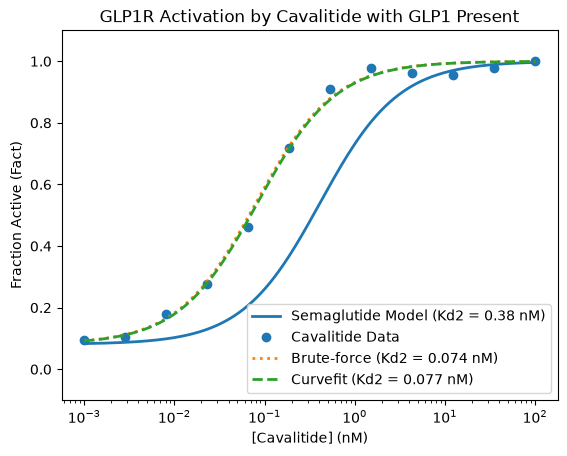

In [4]:
# fit_cavalitide_GLP1R.py

import numpy as np  #import numpy as np
import matplotlib.pyplot as plt #import matplotlib.pyplot as plt
from scipy.optimize import curve_fit #from scipy.optimize import curve_fit

def Fact(L1, L2, Kd1, Kd2): #def Fact(L1, L2, Kd1, Kd2):
    """Fractional Receptor Activation with Two Agonists L1 and L2""" 
    return (Kd2*L1+Kd1*L2) / (Kd1*Kd2 + Kd2*L1 + Kd1*L2) #return (Kd2*L1+Kd1*L2) / (Kd1*Kd2 + Kd2*L1 + Kd1*L2)

# Parameters [nM]
Kd1 = 0.17 # L1, GLP1
Kd2 = 0.38 # semaglutide Kd, for comparison (L2 = cavalitide is fitted below)
L1 = 0.015 # [nM] GLP1 (fasting)
L2 = np.logspace(-3, 2, 500) # [nM] semaglutide or cavalitide

# Load the data
data = np.loadtxt("cavalitide_data.csv", delimiter=",", skiprows=1) # define data variable by loading the CSV file
L2_loaded, Fact_loaded = data[:, 0], data[:, 1] # define L2_loaded and Fact_loaded variables from the data array

# Approach 1: Brute force optimization of Kd2: try many candidate values in a for loop
Kd2_candidates = np.logspace(-3, 2, 100) # [nM]
SSE_brute = np.inf # initialize SSE_brute to infinity
for Kd2_try in Kd2_candidates: # iterate through each candidate Kd2 value
    # Sum of squared errors between the data and the model for this candidate
    SSE = np.sum((Fact_loaded - Fact(L1, L2_loaded, Kd1, Kd2_try))**2) # calculate the sum of squared errors for this candidate
    if SSE < SSE_brute: # check if this candidate has a lower SSE than the current best
        SSE_brute = SSE # update the best SSE
        Kd2_brute = Kd2_try # update the best Kd2 candidate
print(f"Brute-force Kd2 = {Kd2_brute:.3f} nM (SSE = {SSE_brute:.4f})") # print the best brute-force Kd2 and its SSE

# Approach 2: Python curvefit of Kd2: related to steepest descent method
popt, pcov = curve_fit(lambda L2, Kd2: Fact(L1, L2, Kd1, Kd2), # define the curve fit function
                       L2_loaded, Fact_loaded, p0=[0.1], bounds=(0, np.inf)) # fit the curve to the data with initial guess and bounds
Kd2_fit = popt[0] # extract the fitted Kd2 value from the optimization results
SSE_fit = np.sum((Fact_loaded - Fact(L1, L2_loaded, Kd1, Kd2_fit))**2) # calculate the sum of squared errors for the fitted Kd2
print(f"Fitted Kd2 = {Kd2_fit:.3f} nM (SSE = {SSE_fit:.4f})") # print the fitted Kd2 and its SSE


plt.figure() # create a new figure for plotting
line, = plt.semilogx(L2, Fact(L1, L2, Kd1, Kd2), lw=2, # plot the semaglutide model on a log scale
                     label=f"Semaglutide Model (Kd2 = {Kd2} nM)") # label the semaglutide model with its Kd2 value
plt.semilogx(L2_loaded, Fact_loaded, "o", c=line.get_color(), # plot the cavalitide data on a log scale
             label="Cavalitide Data") # label the cavalitide data
plt.semilogx(L2, Fact(L1, L2, Kd1, Kd2_brute), ":", lw=2, # plot the brute-force model on a log scale
             label=f"Brute-force (Kd2 = {Kd2_brute:.3f} nM)") # label the brute-force model with its Kd2 value
plt.semilogx(L2, Fact(L1, L2, Kd1, Kd2_fit), "--", lw=2, # plot the curvefit model on a log scale
             label=f"Curvefit (Kd2 = {Kd2_fit:.3f} nM)") # label the curvefit model with its Kd2 value
plt.ylim(-0.1, 1.1) # set the y-axis limits
plt.xlabel("[Cavalitide] (nM)") # set the x-axis label
plt.ylabel("Fraction Active (Fact)") # set the y-axis label
plt.title("GLP1R Activation by Cavalitide with GLP1 Present") # set the plot title
plt.legend(loc="lower right") # display the legend in the upper left corner
plt.show() # display the plot

<div class="alert alert-block alert-success">
<b>Conclusions:</b>  Evidently, the fitted value of Kd for Cavalitide is 0.077 nM, while the value of Kd for semaglutide is 0.38 nM. Because the value of Kd is the concentration of the drug needed to bind 50% of GLP1R, a drug with a lower Kd has a higher binding affinity for the GLP1R, and a lower dose will be required to have the same intended effects, which would be more cost-effective, as well as limit off-target side effects. Hence, Cavalitide seems to be more potent than semaglutide. On the other hand, GLP1R becomes nearly fully activated at very low Cavalitide concentrations. As a result, there is less room for error in regards to proper dosing.
</div>

## Task 2: Simulate the pharmacokinetics of Cavalitide treatment

Your boss is really excited about the progress of your team in Task 1 on the development of
Cavalitide. You’re now assigned to help design the Phase 1 clinical trial for the pill version
of Cavalitide.

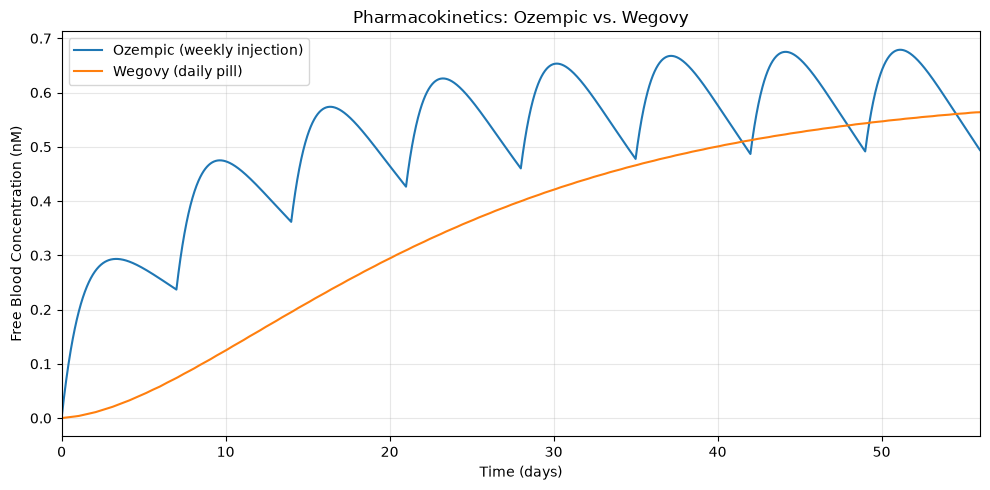

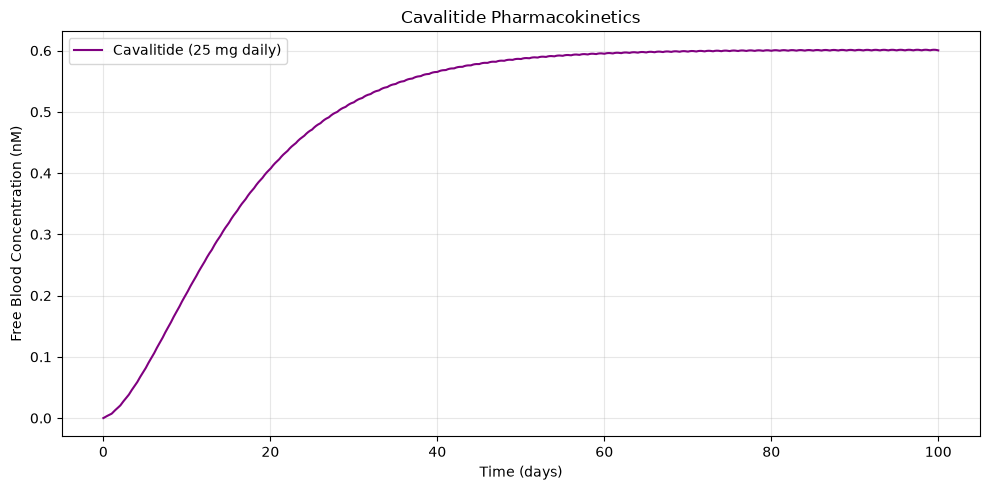

Original daily dose: 25 mg
Original average free concentration: 0.6011 nM
Optimized daily dose: 20.8 mg

Optimized average free concentration: 0.5 nM
Minimum free concentration: 0.4994 nM
Maximum free concentration: 0.5003 nM


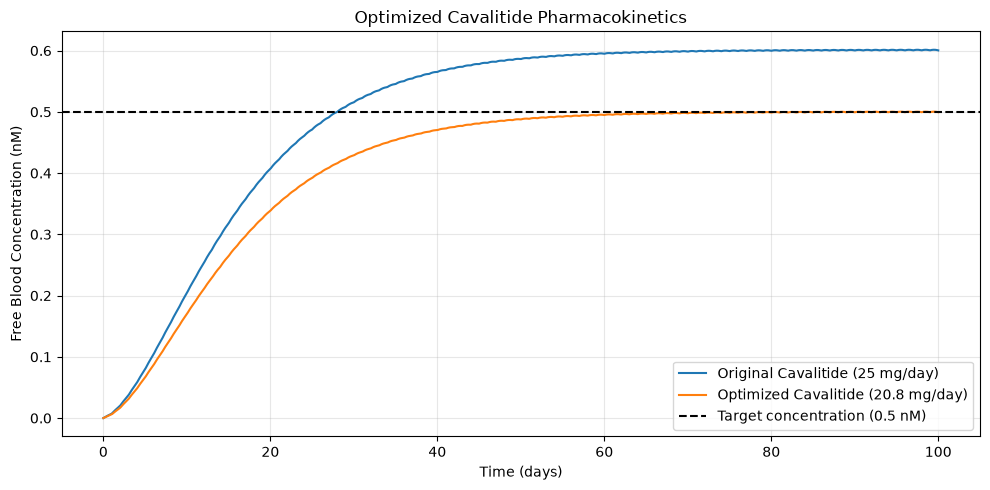


Predicted Cavalitide receptor occupancy: 86.66 %


In [3]:
# importing required libraries
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# defining drug-specific parameters
products = {
    'Ozempic': {
        'Favailable': 0.89, # bioavailability
        'ka': 0.029, # absorption rate (1/h)
        'D': 2.0, # dose (mg)
        'interval': 168, # weekly dosing (hours)
        'n_doses': 8
    },
    'Wegovy': {
        'Favailable': 0.01,
        'ka': 0.0029,
        'D': 25,
        'interval': 24, # daily dosing (hours)
        'n_doses': 100
    }
}

# defining shared pharmacokinetic parameters

ke = 0.0039 # elimination rate constant (1/h)
V = 10.8 # volume of distribution (L)
MW = 4113.6 # molecular weight (g/mol)
Ffree = 0.01 # fraction of drug that is free in blood

# defining differential equations where Asc = amount of drug in the absorption depot in mg, Cc = total blood conc. in mg/L

def ODEfunc(t,y,ka):
    Asc, Cc = y

    dAsc = -ka * Asc
    dCc = (ka * Asc / V) - (ke * Cc)

    return [dAsc, dCc]

# creating simulation function using solve_ivp to replace the Euler method. Each dose is added to the depot at the beginning of its dosing interval and solve_ivp calculates absorption and elimination throughout that interval.

def simulate(Favailable, ka, D, interval, n_doses):
    #lists storing simulation results
    t_out = []
    Asc_out = []
    Cc_out = []

    #initial conditions (no drug in bloodstream or depot)
    y = np.array([0.0, 0.0])

    #simulating each dosing interval
    for i in range(n_doses):
        y[0] += Favailable * D #adding the bioavailable portion of the dose to the depot

        t0 = i * interval
        t1 = (i + 1) * interval #beginning and end of the current dosing interval

        t_eval = np.linspace(t0, t1, 401) #time points at which to save the solution

        # numerically solving the diff. eq.
        sol = solve_ivp(
            ODEfunc,
            (t0, t1),
            y,
            args=(ka,),
            t_eval=t_eval,
            method='RK45',
            rtol=1e-8,
            atol=1e-10
        )

        #checking that the numerical solution was successful
        if not sol.success:
            raise RuntimeError(sol.message)

        #storing results without duplicating interval boundaries
        if i == 0:
            t_out.append(sol.t)
            Asc_out.append(sol.y[0])
            Cc_out.append(sol.y[1])
        else:
            t_out.append(sol.t[1:])
            Asc_out.append(sol.y[0, 1:])
            Cc_out.append(sol.y[1, 1:])

        y = sol.y[:, -1].copy() #carrying the final concentrations into the next interval

    #combining the results from all dosing intervals
    t = np.concatenate(t_out)
    Asc = np.concatenate(Asc_out)
    Cc = np.concatenate(Cc_out)

    #converting total blood concentration from mg/L to nM
    Cc_nM = Cc * 1e6 / MW

    #calculating free blood concentration
    Cfree = Ffree * Cc_nM
    return t, Asc, Cc_nM, Cfree

# running simulations for both medication
ozempic = simulate(**products['Ozempic'])
wegovy = simulate(**products['Wegovy'])

# extracting time and free blood concentrations
t_oz = ozempic[0]
Cfree_oz = ozempic[3]
t_weg = wegovy[0]
Cfree_weg = wegovy[3]

#plotting both medications on the same graph
plt.figure(figsize=(10, 5))
plt.plot(t_oz / 24, Cfree_oz, label='Ozempic (weekly injection)')
plt.plot(t_weg / 24, Cfree_weg, label='Wegovy (daily pill)')
plt.xlabel('Time (days)')
plt.ylabel('Free Blood Concentration (nM)')
plt.title('Pharmacokinetics: Ozempic vs. Wegovy')

#showing the first 56 days for clearer comparison
plt.xlim(0, 56)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#simulating cavalitide
cavalitide_params = {
    'Favailable': 0.01,
    'ka': 0.006,
    'D': 25,
    'interval': 24,
    'n_doses': 100
}

cavalitide = simulate(**cavalitide_params) #running the simulation

#extracting time and free blood concentration
t_cav = cavalitide[0]
Cfree_cav = cavalitide[3]

#plotting Cavalitide blood concentration over time
plt.figure(figsize=(10, 5))
plt.plot(t_cav / 24, Cfree_cav, label='Cavalitide (25 mg daily)', color='purple')
plt.xlabel('Time (days)')
plt.ylabel('Free Blood Concentration (nM)')
plt.title('Cavalitide Pharmacokinetics')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#optimizing cavalitide dosing to get target average steady-state free blood concentration of ~0.5 nM
target = 0.5

#calculating the average free concentration over final 24-hour dosing interval using numerical integration
last_interval = t_cav >= (t_cav[-1] - 24)
current_average = np.trapezoid(Cfree_cav[last_interval], t_cav[last_interval]) / 24

#scaling original dose
original_dose = cavalitide_params['D']
new_dose = original_dose * (target / current_average)
print("Original daily dose:", original_dose, "mg")
print("Original average free concentration:", round(current_average, 4), "nM")
print("Optimized daily dose:", round(new_dose, 2), "mg")

#creating a new set of parameters with the optimized dose
optimized_params = cavalitide_params.copy()
optimized_params['D'] = new_dose

optimized_cav = simulate(**optimized_params) #running the optimized Cavalitide simulation

#extracting optimized results
t_opt = optimized_cav[0]
Cfree_opt = optimized_cav[3]

#verifying the optimized steady-state concentration
#calculating the average concentration during the final 24-hour dosing interval
last_interval_opt = t_opt >= (t_opt[-1] - 24)
final_average = np.trapezoid(Cfree_opt[last_interval_opt], t_opt[last_interval_opt]) / 24

#calculating the min and max conc. during the final dosing interval to show fluctuations
final_min = np.min(Cfree_opt[last_interval_opt])
final_max = np.max(Cfree_opt[last_interval_opt])

print("\nOptimized average free concentration:", round(final_average, 4), "nM")
print("Minimum free concentration:", round(final_min, 4), "nM")
print("Maximum free concentration:", round(final_max, 4), "nM")

#plotting original and optimized Cavalitide profiles
plt.figure(figsize=(10, 5))
plt.plot(t_cav / 24, Cfree_cav, label='Original Cavalitide (25 mg/day)')
plt.plot(t_opt / 24, Cfree_opt, label='Optimized Cavalitide (' + str(round(new_dose, 2)) + ' mg/day)')

#adding horizontal line representing the target concentration
plt.axhline(
    y=target,
    linestyle='--',
    color='black',
    label='Target concentration (0.5 nM)'
)
plt.xlabel('Time (days)')
plt.ylabel('Free Blood Concentration (nM)')
plt.title('Optimized Cavalitide Pharmacokinetics')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#connecting the optimized conc. to Task 1 by calculating predicted receptor occupancy using the model from Task 1
Kd_cavalitide = 0.077  # nM
occupancy = (final_average / (Kd_cavalitide + final_average)) * 100
print("\nPredicted Cavalitide receptor occupancy:", round(occupancy, 2), "%")

<div class="alert alert-block alert-success">
<b>Conclusions:</b>  Insert conclusions from task 2.
</div>

## Task 3: Simulate a combined pharmacokinetics-pharmacokinetics (PKPD) model that predicts GLP1 receptor activity during treatment

The Phase 1 clinical trial was a success, and you achieved the desired 0.5 nM
concentration of Cavalitide in your patients. Now it’s time to further customize the dosing
for the Phase 2 clinical trial, where you’re more interested in efficacy. You’ll need to
combine the PK model (Task 2) and PD model (Task 1) to predict how the fraction of
activated receptors changes over time.

Dose: 20.8 mg/day -> Fact at day 100: 86.8 %
Free Cavalitide needed: 0.686 nM
New dose: 28.6 mg/day -> Fact at day 100: 90.0 %


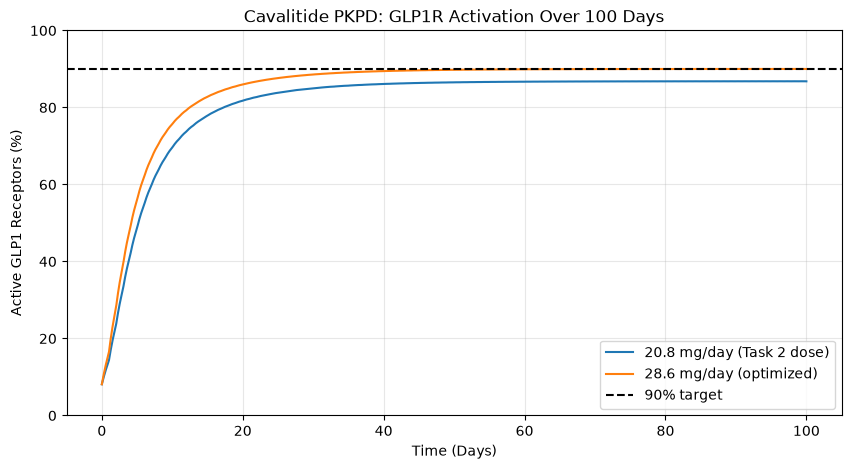

In [9]:
# PD parameters from Task 1
Kd_GLP1 = 0.17    # nM
Kd_cav = 0.077    # nM, fitted Cavalitide Kd
GLP1 = 0.015      # nM, fasting GLP1

def Fact(L2):  # Calculate the fraction of active GLP1 receptors given the free Cavalitide concentration (L2)
    """Fraction of active receptors with GLP1 + Cavalitide (L2, nM)""" # Returns the fraction of active GLP1 receptors as a function of the free Cavalitide concentration
    return (Kd_cav*GLP1 + Kd_GLP1*L2) / (Kd_GLP1*Kd_cav + Kd_cav*GLP1 + Kd_GLP1*L2) # Calculate the fraction of active receptors

t, Asc, Cc, Cfree = simulate(**optimized_params) # Simulate the PKPD model with the Task 2 dose
F = Fact(Cfree) # Calculate the fraction of active receptors for the Task 2 dose
print("Dose:", round(optimized_params['D'], 1), "mg/day -> Fact at day 100:", round(F[-1]*100, 1), "%") # Print the dose and fraction of active receptors at day 100

# Solve Fact = 0.9 for the free concentration needed
target = 0.9 # Target fraction of active receptors
C_needed = (target*Kd_GLP1*Kd_cav - (1 - target)*Kd_cav*GLP1) / ((1 - target)*Kd_GLP1) # Calculate the free Cavalitide concentration needed to achieve the target fraction of active receptors

# Concentration is proportional to dose, so scale the dose to achieve the target free Cavalitide concentration
new_params = optimized_params.copy() # Create a copy of the optimized parameters
new_params['D'] = optimized_params['D'] * C_needed / Cfree[-1] # Scale the dose to achieve the target free Cavalitide concentration

t2, Asc2, Cc2, Cfree2 = simulate(**new_params) # Simulate the PKPD model with the new dose
F2 = Fact(Cfree2) # Calculate the fraction of active receptors for the new dose
print("Free Cavalitide needed:", round(C_needed, 3), "nM") # Print the free Cavalitide concentration needed to achieve the target fraction of active receptors
print("New dose:", round(new_params['D'], 1), "mg/day -> Fact at day 100:", round(F2[-1]*100, 1), "%") # Print the new dose and fraction of active receptors at day 100

# ---- Plot ----
plt.figure(figsize=(10, 5)) # Create a figure for plotting the fraction of active receptors over time
plt.plot(t/24, F*100, label=f"{optimized_params['D']:.1f} mg/day (Task 2 dose)") # Plot the fraction of active receptors for the Task 2 dose
plt.plot(t2/24, F2*100, label=f"{new_params['D']:.1f} mg/day (optimized)") # Plot the fraction of active receptors for the optimized dose
plt.axhline(90, ls='--', color='k', label='90% target') # Add a horizontal line at the 90% target fraction of active receptors
plt.xlabel('Time (Days)') # Label the x-axis as time in days
plt.ylabel('Active GLP1 Receptors (%)') # Label the y-axis as the fraction of active GLP1 receptors in percent
plt.title('Cavalitide PKPD: GLP1R Activation Over 100 Days') # Set the title for the plot
plt.ylim(0, 100) # Set the y-axis limits from 0 to 100 percent
plt.legend() # Add a legend to identify the plotted lines
plt.grid(alpha=0.3) # Add a grid to the plot
plt.show() # Display the plot

<div class="alert alert-block alert-success">
<b>Conclusions:</b>  To build the combined Cavalitide PKPD model, the free blood concentration of Cavalitide from the PK model in Task 2 was used as the drug concentration in the receptor binding model from Task 1. For Cavalitide, natural GLP1, and fasting GLP1 concentration, we used Kd = 0.077 nM, Kd = 0.17 nM, and a concentration of 0.015 nM, respectively. In the plot above of Cavalitide PKPD: GLP1R Activation Over 100 Days, it is evident that before treatment, the percentage of active GLP1Rs due to naturally occurring GLP1 was approximately 8%. When given the Task 2 dosage of 20.8 mg/day, the percentage of active GLP1Rs increased to approximately 86.8% between days 0 and 35, where it then displayed an asymptotic behavior until day 100, represented by the blue line. Because the Kd of Cavalitide, 0.077 nM, is much lower than the steady-state free concentration of 0.5 nM, the GLP1Rs are activated faster than Cavalitide accumulates in the blood. Then, we further optimized our dosing strategy so that we could achieve close to 90% active GLP1Rs at steady-state around 100 days. The only dosing parameter that was altered was the daily dose, which we changed from 20.8 to 28.6 mg/day. This modification raised the steady-state free concentration from 0.5 nM to 0.686 nM because the increase in dosage meant that the body was not removing enough Cavalitide to balance the larger daily input, so the concentration rose to maintain equilibrium between absorption and excretion. This alteration led to 90% of the GLP1Rs being activated at steady state, increasing approximately between days 0 and 35, where it then displayed an asymptotic behavior until day 100, represented by the orange line. There are numerous clinical benefits that occur due to this adjustment. For instance, the higher GLP1R activation percentage due to the optimized dosage of 28.6 mg/day of Cavalitide results in stronger effects of the drug, including appetite suppression and effective insulin regulation. Hence, more weight loss may be observed, which in turn may lower the risk of additional clinical problems such as Type 2 Diabetes, cardiovascular complications, as well as other conditions discussed in the Disease Background section. However, increasing the dosage from 20.8 mg/day to 28.6 mg/day could lead to stronger unintended side effects, such as nausea. Additionally, it may lead to excess costs for the manufacturer, patients, and other stakeholders involved.
</div>

## Conclusions:

Explain what your analyses suggest about the potential for Cavalitide in competition with semaglutide (oral or injected).

## Limitations and Future Work:

Describe the limitations of your project. If you had more time or additional data, explain how you would improve the analysis.

## AI Usage Statement:
- We used Claude to help debug some of the code in the Tasks sections, though only minimally. It was helpful because most of the issues were minor, such as syntax errors. It also was helpful for putting the Semaglutide Model onto the Cavalitide Model for ease of comparison. 

## GitHub Repository Link:
https://github.com/julialundy/BME2315_Module3.git 


## References:

1. Ahmed SK, Mohammed RA. Obesity: prevalence, causes, consequences, management, preventive strategies and future research directions. Metab Open. 2025;27:100375. doi:10.1016/j.metop.2025.100375. PubMed

2. Eunice Kennedy Shriver National Institute of Child Health and Human Development. How are obesity & overweight diagnosed? National Institutes of Health. Published July 28, 2021. Accessed November 5, 2026. NICHD

3. Pillarisetti L, Agrawal DK. Semaglutide: double-edged sword with risks and benefits. Arch Intern Med Res. 2025;8(1):1-13. doi:10.26502/aimr.0189.

## NOTES FROM YOUR TEAM: 
*This is where our team is taking notes and recording activity.*

## QUESTIONS FOR YOUR TA: 
*These are questions we have for our TA.*